In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

In [2]:
df=pd.read_csv("/Users/pruthvi/Desktop/ML_practical/winequality.csv")
df

,type,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,white,7.0,0.270,0.36,20.7,0.045,45.0,170.0,1.00100,3.00,0.45,8.8,6
1,white,6.3,0.300,0.34,1.6,0.049,14.0,132.0,0.99400,3.30,0.49,9.5,6
2,white,8.1,0.280,0.40,6.9,0.050,30.0,97.0,0.99510,3.26,0.44,10.1,6
3,white,7.2,0.230,0.32,8.5,0.058,47.0,186.0,0.99560,3.19,0.40,9.9,6
4,white,7.2,0.230,0.32,8.5,0.058,47.0,186.0,0.99560,3.19,0.40,9.9,6
...,...,...,...,...,...,...,...,...,...,...,...,...,...
6492,red,6.2,0.600,0.08,2.0,0.090,32.0,44.0,0.99490,3.45,0.58,10.5,5
6493,red,5.9,0.550,0.10,2.2,0.062,39.0,51.0,0.99512,3.52,NaN,11.2,6
6494,red,6.3,0.510,0.13,2.3,0.076,29.0,40.0,0.99574,3.42,0.75,11.0,6
6495,red,5.9,0.645,0.12,2.0,0.075,32.0,44.0,0.99547,3.57,0.71,10.2,5


In [3]:
df.isnull().sum()

type                     0
fixed acidity           10
volatile acidity         8
citric acid              3
residual sugar           2
chlorides                2
free sulfur dioxide      0
total sulfur dioxide     0
density                  0
pH                       9
sulphates                4
alcohol                  0
quality                  0
dtype: int64

In [4]:
df1=df.fillna(method="ffill")
df1.isnull().sum()

/var/folders/hq/pjvp1t4n0gjcx7x_0m4shdqc0000gn/T/ipykernel_3194/3369953911.py:1: FutureWarning: DataFrame.fillna with 'method' is deprecated and will raise in a future version. Use obj.ffill() or obj.bfill() instead.
  df1=df.fillna(method="ffill")


type                    0
fixed acidity           0
volatile acidity        0
citric acid             0
residual sugar          0
chlorides               0
free sulfur dioxide     0
total sulfur dioxide    0
density                 0
pH                      0
sulphates               0
alcohol                 0
quality                 0
dtype: int64

In [5]:
y=df1['type']
x=df1.drop(['type'],axis=1)

In [6]:
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split

In [7]:
x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=0.2,random_state=0)

In [8]:
scaler=StandardScaler()
x_scaled=scaler.fit_transform(x)

In [9]:
pca=PCA(n_components=2)
x_pca=pca.fit_transform(x_scaled)

In [10]:
print(y.unique)

<bound method Series.unique of 0       white
1       white
2       white
3       white
4       white
        ...  
6492      red
6493      red
6494      red
6495      red
6496      red
Name: type, Length: 6497, dtype: object>


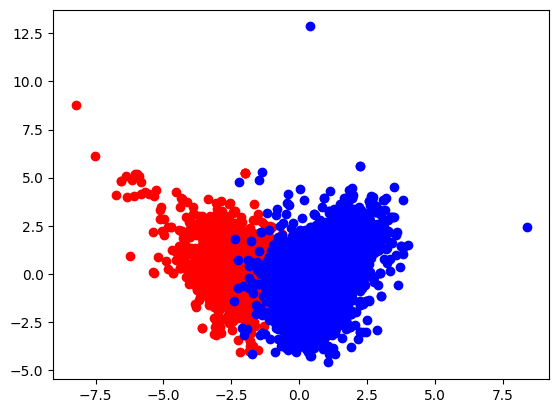

In [11]:
plt.scatter(x_pca[y == 'red',0],x_pca[y == 'red',1],label="red wine",c="red")
plt.scatter(x_pca[y == 'white',0],x_pca[y == 'white',1],label="white wine",c="blue")

In [12]:
from sklearn.linear_model import LogisticRegression


x_train_scaled = scaler.transform(x_train)
x_test_scaled = scaler.transform(x_test)


x_train_pca = pca.transform(x_train_scaled)
X_test_scaled = pca.transform(x_test_scaled)


model = LogisticRegression(random_state=0)
model.fit(x_train_pca, y_train)


y_pred = model.predict(X_test_scaled)

In [13]:
from sklearn.metrics import accuracy_score

y_test_numeric = y_test.apply(lambda x: 1 if x == 'white' else 0)
y_pred_numeric = pd.Series(y_pred).apply(lambda x: 1 if x == 'white' else 0)


accuracy = accuracy_score(y_test_numeric, y_pred_numeric)

print("Accuracy :", accuracy)

Accuracy : 0.9792307692307692


In [14]:
print("Accuracy : {:.2f}%".format(accuracy * 100))

Accuracy : 97.92%
